# Chapter 2. Background Research
## 2.3 Noise-Level Estimation
This notebook demonstrates Laplacian-based, wavelet-based, and block-based noise estimation. The examples focus on how each estimator responds to image content.

These examples use synthetic Gaussian noise. The true noise level is known and can be compared directly with the estimate.

In [7]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pywt
from scipy.signal import convolve2d
from matplotlib.colors import PowerNorm
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap

# Find the project directory
if Path.cwd().name == "notebooks":
    project_dir = Path.cwd().parent
else:
    project_dir = Path.cwd()

sys.path.append(str(project_dir))

from src.noise import add_gaussian_noise
from src.noise_level_estimators import (
    laplacian_noise_estimate,
    wavelet_noise_estimate,
    block_noise_estimate
)
from src.utils import load_grayscale_image

# Set the data and output folders
test_dir = project_dir / "data" / "background_research_examples"
plot_dir = project_dir / "results" / "Chapter2_NoiseEstimation"
os.makedirs(plot_dir, exist_ok=True)

### 2.3.1 Laplacian-Based Estimation

The Laplacian responds strongly to rapid intensity changes. The example compares this response across different image content.


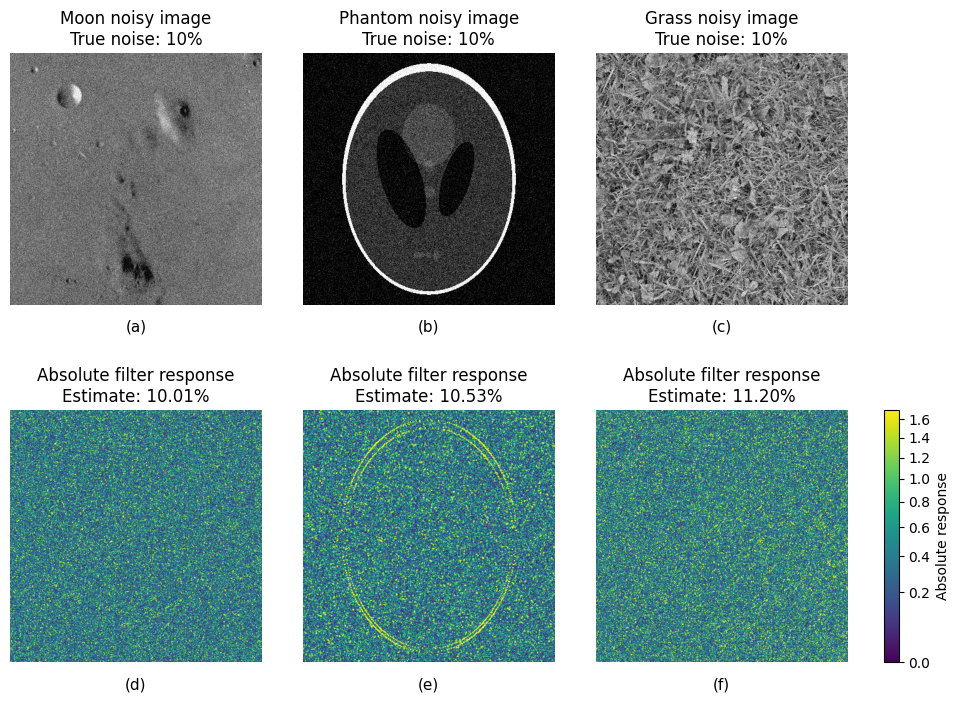

True noise level: 10.00%
Moon      Estimate:  10.01%  Error:  +0.01
Phantom   Estimate:  10.53%  Error:  +0.53
Grass     Estimate:  11.20%  Error:  +1.20


In [11]:
# Select three types of image content
image_files = ["moon.png", "phantom.png", "grass.png"]
image_names = ["Moon", "Phantom", "Grass"]

# Add Gaussian noise at 10%
noise_percent = 10
sigma = noise_percent / 100.0

# Define the noise-estimation kernel
kernel = np.array([
    [1, -2, 1],
    [-2, 4, -2],
    [1, -2, 1]
])

results = []

# Process each image
for image_file, image_name in zip(image_files, image_names):
    clean_image = load_grayscale_image(
        os.path.join(test_dir, image_file)
    )
    noisy_image = add_gaussian_noise(clean_image,sigma=sigma,seed=42)

    # Calculate the filter response
    response = convolve2d(
        noisy_image,
        kernel,
        mode="valid"
    )
    absolute_response = np.abs(response)

    # Estimate the noise level
    estimated_sigma = laplacian_noise_estimate(noisy_image)

    results.append({
        "name": image_name,
        "noisy": noisy_image,
        "response": absolute_response,
        "estimate": estimated_sigma
    })

# Use the same response scale
all_responses = np.concatenate([
    result["response"].ravel() for result in results
])
response_limit = np.percentile(all_responses, 99)

# Improve the contrast of small responses
response_norm = PowerNorm(gamma=0.6,vmin=0,vmax=response_limit)

# Create the figure
fig, axes = plt.subplots(2, 3,figsize=(10, 7))

for col, result in enumerate(results):
    # Show the noisy image
    axes[0, col].imshow(result["noisy"],cmap="gray",vmin=0,vmax=1)
    axes[0, col].set_title(
        f"{result['name']} noisy image\n"
        f"True noise: {noise_percent}%"
    )

    # Show the absolute response
    response_plot = axes[1, col].imshow(result["response"],cmap="viridis",norm=response_norm)
    axes[1, col].set_title(
        "Absolute filter response\n"
        f"Estimate: {result['estimate'] * 100:.2f}%"
    )

# Add panel labels
panel_labels = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"]

for axis, label in zip(axes.ravel(), panel_labels):
    axis.axis("off")
    axis.text(0.5, -0.06, label, transform=axis.transAxes, ha="center", va="top", fontsize=11)

# Set the figure spacing
fig.subplots_adjust(left=0.03, right=0.90, bottom=0.07, top=0.94, wspace=0.03, hspace=0.42)

# Align the colorbar with the response images
response_position = axes[1, 2].get_position()
colorbar_axis = fig.add_axes([0.92, response_position.y0, 0.015, response_position.height])

colorbar = fig.colorbar(response_plot, cax=colorbar_axis)
colorbar.set_label("Absolute response")

plt.savefig(
    os.path.join(plot_dir, "laplacian_content_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Print the estimates
print(f"True noise level: {noise_percent:.2f}%")

for result in results:
    estimate = result["estimate"] * 100
    error = estimate - noise_percent
    print(
        f"{result['name']:<10}"
        f"Estimate: {estimate:>6.2f}%  "
        f"Error: {error:>+6.2f}"
    )

### 2.3.2 Wavelet-Based Estimation

The finest diagonal wavelet coefficients contain high-frequency information. The example shows the coefficients and their distribution.


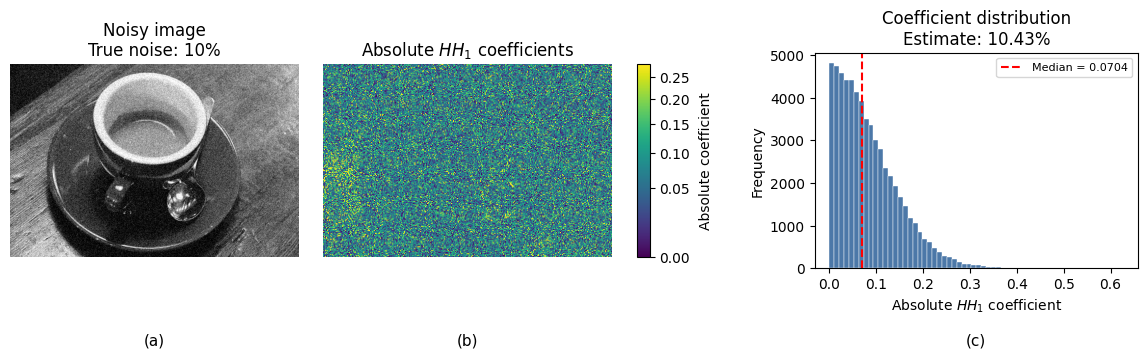

In [9]:
# Load the astronaut image
clean_image = load_grayscale_image(
    os.path.join(test_dir, "coffee.png")
)

# Add Gaussian noise at 10%
noise_percent = 10
sigma = noise_percent / 100.0
noisy_image = add_gaussian_noise(clean_image,sigma=sigma,seed=42)

# Apply a one-level wavelet transform
_, (_, _, diagonal) = pywt.dwt2(
    noisy_image,
    "db1"
)

# Calculate the values used by the estimator
absolute_diagonal = np.abs(diagonal)
median_value = np.median(absolute_diagonal)
estimated_sigma = wavelet_noise_estimate(noisy_image)

# Set the coefficient display range
coefficient_limit = np.percentile(absolute_diagonal, 99)
coefficient_norm = PowerNorm(gamma=0.6,vmin=0,vmax=coefficient_limit)

# Use the input image aspect ratio
image_ratio = noisy_image.shape[0] / noisy_image.shape[1]

# Create separate spaces for the colour bar and histogram
fig = plt.figure(figsize=(12, 4.5))

grid = fig.add_gridspec(1,5,width_ratios=[1, 1, 0.045, 0.40, 1.12],left=0.04,right=0.98,bottom=0.22,top=0.88,wspace=0.12)

axes = [
    fig.add_subplot(grid[0, 0]),
    fig.add_subplot(grid[0, 1]),
    fig.add_subplot(grid[0, 4])
]
colorbar_axis = fig.add_subplot(grid[0, 2])

# Show the noisy image
axes[0].imshow(noisy_image,cmap="gray",vmin=0,vmax=1)
axes[0].set_title(f"Noisy image\nTrue noise: {noise_percent}%")

# Show the HH1 coefficients
coefficient_plot = axes[1].imshow(absolute_diagonal,cmap="viridis",norm=coefficient_norm)
axes[1].set_title(r"Absolute $HH_1$ coefficients")

# Show the coefficient distribution
axes[2].hist(absolute_diagonal.ravel(),bins=60,color="#4C78A8",edgecolor="white",linewidth=0.3)
axes[2].axvline(median_value,color="red",linestyle="--",linewidth=1.5,label=f"Median = {median_value:.4f}")
axes[2].set_title(
    "Coefficient distribution\n"
    f"Estimate: {estimated_sigma * 100:.2f}%"
)
axes[2].set_xlabel(r"Absolute $HH_1$ coefficient")
axes[2].set_ylabel("Frequency")
axes[2].legend(fontsize=8)

# Match the three panel shapes
for axis in axes:
    axis.set_box_aspect(image_ratio)

axes[0].axis("off")
axes[1].axis("off")

# Add the colour bar beside panel (b)
colorbar = fig.colorbar(coefficient_plot,cax=colorbar_axis)
colorbar.set_label("Absolute coefficient",labelpad=6)

# Match the colour bar height to panel (b)
fig.canvas.draw()

coefficient_position = axes[1].get_position()
colorbar_position = colorbar_axis.get_position()

colorbar_axis.set_position([
    colorbar_position.x0,
    coefficient_position.y0,
    colorbar_position.width,
    coefficient_position.height
])

# Place all panel labels on the same line
panel_labels = ["(a)", "(b)", "(c)"]
label_y = 0.15

for axis, label in zip(axes, panel_labels):
    position = axis.get_position()
    label_x = position.x0 + position.width / 2

    fig.text(label_x,label_y,label,ha="center",va="center",fontsize=11)

plt.savefig(
    os.path.join(
        plot_dir,
        "wavelet_noise_estimation.png"
    ),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 2.3.3 Block-Based Estimation

The image is divided into non-overlapping 5 ﷿﷿ 5 blocks. Homogeneous blocks are selected for the estimate. The figure shows which blocks are retained.


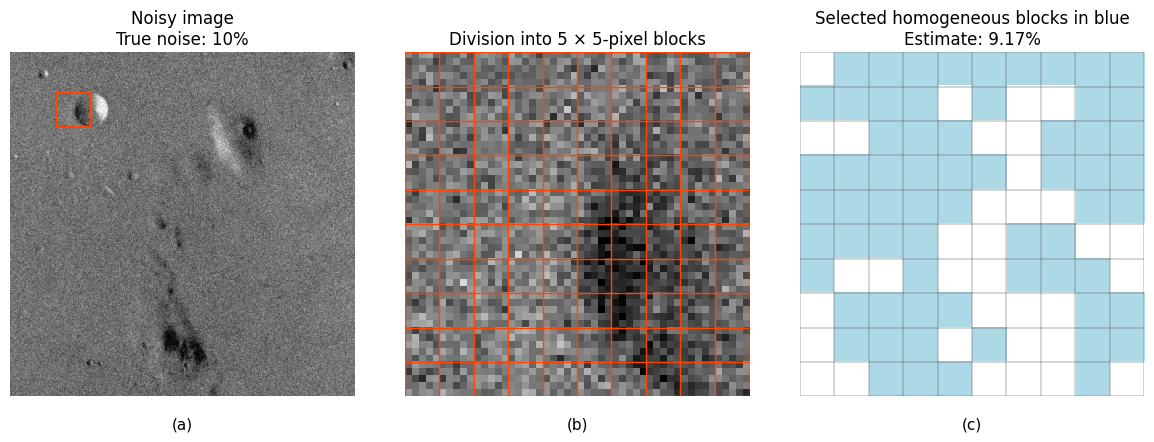

True noise level: 10.00%
Block estimate: 9.17%
Selected blocks: 7456


In [10]:
# Load the image
clean_image = load_grayscale_image(
    os.path.join(test_dir, "moon.png")
)

# Add Gaussian noise
noise_percent = 10
sigma = noise_percent / 100.0
noisy_image = add_gaussian_noise(
    clean_image,
    sigma=sigma,
    seed=42
)

# Estimate noise and return the selected blocks
estimated_sigma, selected_blocks, block_image = block_noise_estimate(noisy_image,return_details=True)

# Select a region aligned with the blocks
start_row = 60
start_col = 70
region_size = 50

end_row = start_row + region_size
end_col = start_col + region_size

zoomed_image = block_image[start_row:end_row, start_col:end_col]

# Find selected blocks inside the enlarged region
zoomed_blocks = []

for row, col in selected_blocks:
    if start_row <= row < end_row and start_col <= col < end_col:
        zoomed_blocks.append((row - start_row, col - start_col))

# Create a mask for the selected blocks
selection_mask = np.zeros_like(zoomed_image)

for row, col in zoomed_blocks:
    selection_mask[row:row + 5, col:col + 5] = 1

# Display the noisy image and enlarged region
fig, axes = plt.subplots(1, 3,figsize=(12, 4))

# Show the full noisy image
axes[0].imshow(noisy_image,cmap="gray",vmin=0,vmax=1)
axes[0].set_title(f"Noisy image\nTrue noise: {noise_percent}%")

# Mark the enlarged region
region_box = Rectangle(
    (start_col, start_row),
    region_size,
    region_size,
    fill=False,
    edgecolor="#FF4500",
    linewidth=1.5
)
axes[0].add_patch(region_box)

# Show the division into 5 ﷿﷿ 5-pixel blocks
axes[1].imshow(zoomed_image,cmap="gray",vmin=0,vmax=1)
axes[1].set_title("Division into 5 ﷿﷿ 5-pixel blocks")

for row in range(0, region_size + 1, 5):
    axes[1].axhline(row - 0.5, color="#FF4500", linewidth=1.0)

for col in range(0, region_size + 1, 5):
    axes[1].axvline(col - 0.5, color="#FF4500", linewidth=1.0)

# Use colours similar to the reference paper
selection_colours = ListedColormap(["#FFFFFF", "#add8e6"])

axes[2].imshow(selection_mask, cmap=selection_colours, vmin=0, vmax=1, interpolation="nearest")


# Draw thin grid lines
for row in range(0, region_size + 1, 5):
    axes[2].axhline(row - 0.5, color="#555555", linewidth=0.35)

for col in range(0, region_size + 1, 5):
    axes[2].axvline(col - 0.5, color="#555555", linewidth=0.35)

axes[2].set_title(
    "Selected homogeneous blocks in blue\n"
    f"Estimate: {estimated_sigma * 100:.2f}%"
)

for axis in axes:
    axis.axis("off")

plt.tight_layout()
plt.savefig(
    os.path.join(plot_dir, "block_selection.png"),
    dpi=300,
    bbox_inches="tight"
)

# Add panel labels
panel_labels = ["(a)", "(b)", "(c)"]

for axis, label in zip(axes, panel_labels):
    axis.text(0.5,-0.06,label,transform=axis.transAxes,ha="center",va="top",fontsize=11)

plt.show()

print(f"True noise level: {sigma * 100:.2f}%")
print(f"Block estimate: {estimated_sigma * 100:.2f}%")
print(f"Selected blocks: {len(selected_blocks)}")